In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
sys.path.append("../src")

os.makedirs("../data", exist_ok=True)

import pandas as pd
pd.set_option("display.max_rows", 200)
from statsbombpy import sb
from xg_pipeline import pull_shots, build_features

comps = sb.competitions()
comps[["competition_id", "season_id", "competition_name", "season_name"]].sort_values(
    ["competition_name", "season_name"])

,competition_id,season_id,competition_name,season_name
1,9,27,1. Bundesliga,2015/2016
0,9,281,1. Bundesliga,2023/2024
2,1267,107,African Cup of Nations,2023
20,16,276,Champions League,1970/1971
19,16,71,Champions League,1971/1972
18,16,277,Champions League,1972/1973
17,16,76,Champions League,1999/2000
16,16,44,Champions League,2003/2004
15,16,37,Champions League,2004/2005
14,16,39,Champions League,2006/2007


In [3]:
m = sb.matches(competition_id=2, season_id=27)   # swap in the IDs you chose
print(len(m), "matches")

380 matches


In [4]:
raw = pull_shots(2, 27, cache_path="../data/shots_league.pkl")
feats = build_features(raw)
feats.to_pickle("../data/features_league.pkl")
print(feats.shape, feats.goal.mean())

25/380 matches done
50/380 matches done
75/380 matches done
100/380 matches done
125/380 matches done
150/380 matches done
175/380 matches done
200/380 matches done
225/380 matches done
250/380 matches done
275/380 matches done
300/380 matches done
325/380 matches done
350/380 matches done
375/380 matches done
(9817, 14) 0.09310379953142509


In [2]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import log_loss, roc_auc_score

d = pd.read_pickle("../data/features_league.pkl").dropna(subset=["defenders_in_cone", "gk_dist_to_goal"])
y = d["goal"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_a = d[["distance", "angle", "is_header"]].join(pd.get_dummies(d["shot_type"], prefix="type").astype(int))
X_b = X_a.join(d[["defenders_in_cone", "gk_dist_to_goal", "nearest_defender"]])

def evaluate(model, X, name):
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:35s} log loss {log_loss(y, p):.4f} | AUC {roc_auc_score(y, p):.4f}")

print(f"{'Constant (no skill)':35s} log loss {log_loss(y, np.full(len(y), y.mean())):.4f}")
evaluate(LogisticRegression(max_iter=2000), d[["distance", "angle"]], "Logistic: distance + angle")
evaluate(LogisticRegression(max_iter=2000), X_a, "Logistic: + header + shot type")
evaluate(LogisticRegression(max_iter=2000), X_b, "Logistic: + freeze-frame")
evaluate(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
         X_b, "Gradient boosting: all features")
print(f"{'StatsBomb xG':35s} log loss {log_loss(y, d.shot_statsbomb_xg):.4f} | AUC {roc_auc_score(y, d.shot_statsbomb_xg):.4f}")

Constant (no skill)                 log loss 0.3088
Logistic: distance + angle          log loss 0.2783 | AUC 0.7320
Logistic: + header + shot type      log loss 0.2711 | AUC 0.7545
Logistic: + freeze-frame            log loss 0.2605 | AUC 0.7809
Gradient boosting: all features     log loss 0.2634 | AUC 0.7737
StatsBomb xG                        log loss 0.2525 | AUC 0.7951


In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
pd.set_option("display.max_rows", 200)
from xg_pipeline import pull_shots, build_features

raw = pd.read_pickle("../data/shots_league.pkl")
feats = build_features(raw)
feats.to_pickle("../data/features_league_v2.pkl")
print(feats.shape)

(9817, 22)


In [3]:
raw = pd.read_pickle("../data/shots_league.pkl")
feats = build_features(raw)
feats.to_pickle("../data/features_league_v2.pkl")
print(feats.shape)

(9817, 22)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import log_loss, roc_auc_score

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

d = pd.read_pickle("../data/features_league_v2.pkl").dropna(subset=["defenders_in_cone", "gk_dist_to_goal"]).copy()
y = d["goal"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

d["log_dist"] = np.log1p(d.distance)   # lets the model bend the distance curve
d["dist_x_angle"] = d.distance * d.angle

base = ["distance", "angle", "is_header", "defenders_in_cone", "gk_dist_to_goal", "nearest_defender"]
flags = ["shot_first_time", "under_pressure", "shot_one_on_one",
         "shot_follows_dribble", "shot_aerial_won", "shot_open_goal"]
cats = pd.get_dummies(d[["shot_type", "shot_technique", "play_pattern"]]).astype(int)

X_b = d[base].join(pd.get_dummies(d["shot_type"], prefix="type").astype(int))
X_c = d[base + flags].join(cats)
X_d = X_c.join(d[["log_dist", "dist_x_angle"]])

def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

def evaluate(model, X, name):
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:35s} log loss {log_loss(y, p):.4f} | AUC {roc_auc_score(y, p):.4f}")

evaluate(logit(), X_b, "Logistic: previous best")
evaluate(logit(), X_c, "Logistic: + context features")
evaluate(logit(), X_d, "Logistic: + curve terms")
evaluate(GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
         X_d, "Gradient boosting: all features")
print(f"{'StatsBomb xG':35s} log loss {log_loss(y, d.shot_statsbomb_xg):.4f} | AUC {roc_auc_score(y, d.shot_statsbomb_xg):.4f}")

Logistic: previous best             log loss 0.2606 | AUC 0.7809
Logistic: + context features        log loss 0.2595 | AUC 0.7799
Logistic: + curve terms             log loss 0.2577 | AUC 0.7845
Gradient boosting: all features     log loss 0.2607 | AUC 0.7763
StatsBomb xG                        log loss 0.2525 | AUC 0.7951


Actual goals: 909 | My xG total: 904.7 | StatsBomb xG total: 897.1


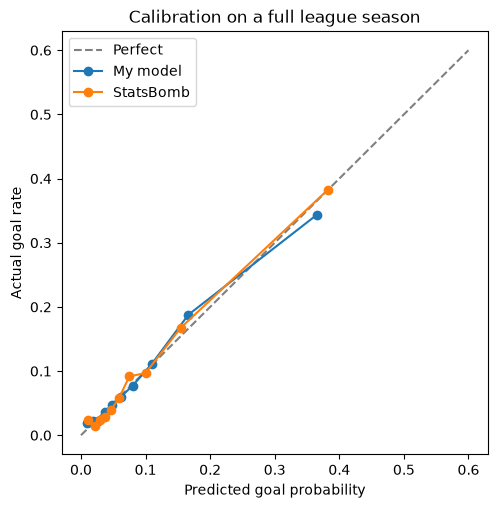

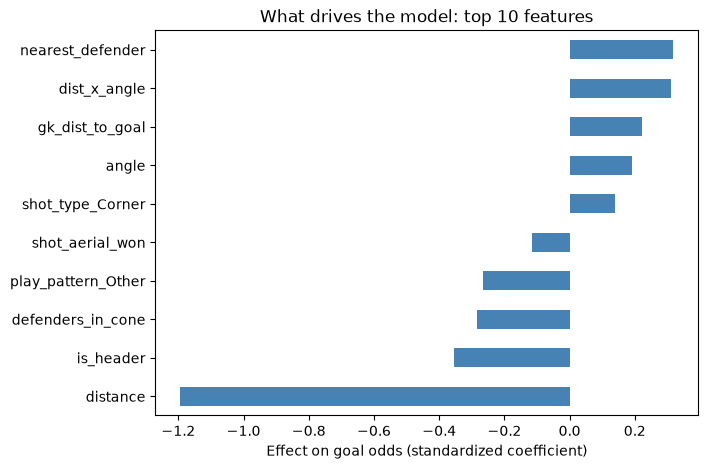

In [6]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

final = logit()
d["my_xg"] = cross_val_predict(final, X_d, y, cv=cv, method="predict_proba")[:, 1]

# Sanity check: totals should be close to each other
print("Actual goals:", y.sum(), "| My xG total:", round(d.my_xg.sum(), 1),
      "| StatsBomb xG total:", round(d.shot_statsbomb_xg.sum(), 1))

# Calibration: mine vs. StatsBomb
plt.figure(figsize=(5.5, 5.5))
plt.plot([0, 0.6], [0, 0.6], "--", color="gray", label="Perfect")
for probs, label in [(d.my_xg, "My model"), (d.shot_statsbomb_xg, "StatsBomb")]:
    frac, pred = calibration_curve(y, probs, n_bins=10, strategy="quantile")
    plt.plot(pred, frac, marker="o", label=label)
plt.xlabel("Predicted goal probability")
plt.ylabel("Actual goal rate")
plt.title("Calibration on a full league season")
plt.legend()
plt.savefig("../figures/calibration_league.png", dpi=150, bbox_inches="tight")
plt.show()

# Which features matter most (the interpretability payoff)
final.fit(X_d, y)
coefs = pd.Series(final.named_steps["logisticregression"].coef_[0], index=X_d.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:10]).sort_values()
top.plot.barh(figsize=(7, 5), color="steelblue")
plt.xlabel("Effect on goal odds (standardized coefficient)")
plt.title("What drives the model: top 10 features")
plt.savefig("../figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()